# Canal 2: is the predicted uncertainty informative about the error, beyond the predicted mean?

Reads the outputs of `snake/scripts/canals/canal2_uncertainty_precompute.py`. The configuration cell below sets which run and which uncertainty source.

Everything is on the model's own output scale: `mu = X`, `y = layers["y"]`, `u = sqrt(variance)`. The correlations are rank-based, so a per-run constant divisor would change none of them. Only the mean errors (`mean_err`) carry units, and they compare between heads of the same family only.

## The three error cases

| case | formula | population |
|---|---|---|
| `lin_all` | \|y − mu\| | ALL (spot, gene) entries, zeros included |
| `lin_pos` | \|y − mu\| | y > 0 only |
| `log_pos` | \|log y − log mu\| | y > 0 only, mu substituted where log(mu) does not exist |

`lin_pos` shares its definition with `lin_all` and its population with `log_pos`, which is what makes a gap with either one attributable to one of the two.

On `lin_all` the partial is the number to read: at y = 0 the error IS the prediction (\|mu − 0\| = \|mu\|), so on most entries the error is a function of `mu` alone and the naive value tends to the mu-u coupling by construction.

## The two grouping axes

- **GENE axis**, group = (gene, slide): with the gene fixed, does the uncertainty rank the error across SPOTS?
- **SPOT axis**, group = (slide, spot): with the spot fixed, does the uncertainty rank the error across GENES?

A head is degenerate on the axis along which its variance parameter is constant: `u` is then constant there, or a monotone function of `mu`, `r_um = ±1`, the denominator collapses and the partial is NaN by construction. That is the correct answer, not a failure, and it is why both axes are reported: one axis alone would leave such a head unmeasured for a reason about the axis rather than about the head.

The control is weaker on the spot axis. With the spot fixed, `mu` varies over several orders of magnitude across genes, and gene identity carries its own dispersion and detection rate, neither of which removing `mu` eliminates.

## Per-donor aggregation

`summary.json` gives one scalar per (axis, case). `pair_partial.parquet` and `spot_partial.parquet` carry the per-group value, so folding slide into donor (`snake/config/donor_slide_map.yaml`) gives the K per-donor points and the Student-t interval used everywhere else. The aggregation cascade is the script's; the donor boundary is added here.

In [13]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)
from src.evaluation.benchmark_summary import donor_lopo_stats

# ââââââââââââââââââââââââââââ SETTINGS ââââââââââââââââââââââââââââââââ
RUN_ID      = "pr_classic3"
RESULTS     = PROJ / "results"
DATASETS    = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS      = "r75"
# The canal2 subfolder to read. ONE at a time: this is the choice of the uncertainty SOURCE.
#   canal2_uncertainty        the model's own head (pred_var / dispersion)
#   canal2_epistemic          MC-dropout epistemic      canal2_aleatoric_mc / canal2_total_mc
#   canal2_laplace_{source}   Laplace                     canal2_knn_{signal}  kNN
CANAL2      = "canal2_uncertainty"
LAMBDA_KEEP = 0.0            # the Gaussian heads carry a beta-NLL sweep; 0.0 IS the true NLL
MODELS      = ["homoscedastic", "heteroscedastic", "spot_homoscedastic", "poisson_cp",
               "negativebinomial_hetero_noanchor_cp", "negativebinomial_spotdisp_cp",
               "negativebinomial_genedisp_cp"]
# Depth-blind: their Delta is measured against a target that carries the spot's library
# size. Separate table, NEVER the same figure or the same axis as the _cp heads.
RAW_MODELS  = ["poisson_raw", "negativebinomial_hetero_noanchor_raw"]
FIGDIR      = PROJ / "results" / "_analysis" / "figures"   # canal 1 convention
# âââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââ

N_PLUS_MIN = 60      # the script's inclusion filter, RE-APPLIED here: the parquets carry ALL
                     # the groups present, filtering is the reader's job
CONVENTION = "v3_native_scale"

CASES = ["lin_all", "lin_pos", "log_pos"]
CASE_LABELS = {"lin_all": "|y - mu|  all entries (zeros included)",
               "lin_pos": "|y - mu|  y > 0",
               "log_pos": "|log y - log mu|  y > 0"}
# The group size depends on the case's POPULATION, not only on the axis.
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
AXES = ["gene", "spot"]

# On which axis each head is mute, and why. These lines ARE the structural claim
# of the section; the last cell checks them against the data instead of assuming them.
DEGENERATE_WHY = {
    "msemeanonly":                  ("both", "no predictive distribution (is_probabilistic=False)"),
    "homoscedastic":                ("gene", "one sigma^2 per GENE -> constant within a (gene,slide) pair"),
    "negativebinomial_genedisp_cp": ("gene", "alpha per GENE -> u = mu + alpha*mu^2 monotone in mu within a gene"),
    "spot_homoscedastic":           ("spot", "one sigma^2 per SPOT -> constant within a spot"),
    "negativebinomial_spotdisp_cp": ("spot", "alpha per SPOT -> u monotone in mu within a spot"),
    "poisson_cp":                   ("both", "u = mu exactly, no free parameter"),
    "poisson_raw":                  ("both", "u = mu exactly, no free parameter"),
}

# Canonical model -> color map, keyed on model_type.
# One color per model across the WHOLE report.
MODEL_COLORS = {
    "homoscedastic":                        "#1f77b4",   # blue
    "heteroscedastic":                      "#ff7f0e",   # orange
    "spot_homoscedastic":                   "#2ca02c",   # green
    "poisson_cp":                           "#d62728",   # red
    "negativebinomial_hetero_noanchor_cp":  "#9467bd",   # violet
    "negativebinomial_spotdisp_cp":         "#e377c2",   # rose
    "negativebinomial_genedisp_cp":         "#17becf",   # cyan
    "poisson_raw":                          "#d62728",
    "negativebinomial_hetero_noanchor_raw": "#9467bd",
}
MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
    "negativebinomial_spotdisp_cp":         "NB, dispersion per spot",
    "negativebinomial_genedisp_cp":         "NB, dispersion per gene",
    "poisson_raw":                          "Poisson (raw counts)",
    "negativebinomial_hetero_noanchor_raw": "Negative binomial (raw counts)",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

# ââ slide -> donor ââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââ
# SPLIT unit = donor, METRIC unit = slide (src/data/splitting.py), so canal2's
# per-slide groups are folded onto donors before any interval. A dataset absent from
# the map = 1 donor per slide.
DONOR_MAP = yaml.safe_load((PROJ / "snake" / "config" / "donor_slide_map.yaml").read_text())

def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}

# ââ discovery ââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââââ
def canal2_runs(ds, models):
    base = RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS
    out = []
    if not base.is_dir():
        return out
    for model_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        if model_dir.name not in models:
            continue
        for leaf in [model_dir] + sorted(model_dir.glob("lambda_*")):
            lam = leaf.name if leaf.name.startswith("lambda_") else None
            if lam is not None and LAMBDA_KEEP is not None:
                if not np.isclose(float(lam[len("lambda_"):]), LAMBDA_KEEP):
                    continue
            if (leaf / CANAL2 / "summary.json").is_file():
                out.append(dict(dataset=ds, model_type=model_dir.name, lambda_dir=lam,
                                dir=leaf / CANAL2))
    return out

RUNS, na_runs, stale = [], [], []
for ds in DATASETS:
    for r in canal2_runs(ds, MODELS + RAW_MODELS):
        s = json.loads((r["dir"] / "summary.json").read_text())
        if s.get("not_applicable"):
            na_runs.append((r["dataset"], r["model_type"], s.get("reason", "")))
            continue
        # GUARD: an artifact tagged with another convention was written with other column names
        # on another scale. Mixing it in silently would be the only way to get it wrong without
        # noticing, so it is dropped by name.
        if s.get("canal2_convention") != CONVENTION:
            stale.append((r["dataset"], r["model_type"], s.get("canal2_convention")))
            continue
        r["summary"] = s
        RUNS.append(r)

# The per-group parquets, read ONCE each (a few tens of thousands of rows): all the rest of
# the notebook re-slices them in memory, so it runs in seconds.
PAIR = {(r["dataset"], r["model_type"]): pd.read_parquet(r["dir"] / "pair_partial.parquet")
        for r in RUNS if (r["dir"] / "pair_partial.parquet").is_file()}
SPOT = {(r["dataset"], r["model_type"]): pd.read_parquet(r["dir"] / "spot_partial.parquet")
        for r in RUNS if (r["dir"] / "spot_partial.parquet").is_file()}
SUMM = {(r["dataset"], r["model_type"]): r["summary"] for r in RUNS}
ALL_MODELS = MODELS + RAW_MODELS

print(f"canal2 = {CANAL2!r}   under {RESULTS.relative_to(PROJ)}")
for ds in DATASETS:
    got = sorted(m for (d, m) in SUMM if d == ds)
    miss = [m for m in ALL_MODELS if m not in got]
    print(f"  {ds:<12s} {len(got):>2d} runs   missing: {miss if miss else '-'}")
if na_runs:
    print(f"\n{len(na_runs)} run(s) 'not_applicable' (canal 2 does not apply to them, this is not a failure):")
    for ds, m, why in na_runs:
        print(f"    {ds:<12s} {m:<40s} {why}")
if stale:
    print(f"\n(!) {len(stale)} run(s) NOT conforming to canal2_convention={CONVENTION!r} -- DROPPED:")
    for ds, m, c in stale:
        print(f"    {ds:<12s} {m:<40s} convention read : {c!r}")
    print("    -> rerun canal2 on these runs; their columns are not the ones read here.")
_miss_pair = [k for k in SUMM if k not in PAIR]
_miss_spot = [k for k in SUMM if k not in SPOT]
if _miss_pair or _miss_spot:
    print(f"\n(!) without pair_partial : {_miss_pair}\n(!) without spot_partial : {_miss_spot}")

canal2 = 'canal2_uncertainty'   under results
  10x_TuPro     9 runs   missing: -
  TLS           9 runs   missing: -
  LUNG_CANCER   9 runs   missing: -


## 1. Population and provenance

To be read BEFORE any correlation number, because these rows fix what "the error" means in each run.

- **`report_axis`**: the axis on which `mu`, `y` and the errors live. It DIFFERS across families, and that is intended: nothing is converted. No effect on the correlations (rank invariance), but the mean errors compare only within a family.
- **`pct_positive`**: the share of entries with y > 0. It is what `lin_all` includes and what the two `_pos` cases drop, and it is exactly the regime where the count families stand out.
- **`floor` / `pct_substituted`**: the floor applies only to `log_pos`, and ONLY where `log(mu)` does not exist (mu â¤ 0). A count head has `mu = exp(f(x)) > 0`, hence 0 % by construction; only the Gaussians trigger it.
- **`floor_sensitivity`**: the gene axis `log_pos` partial recomputed with a substitute twice as small and twice as large. If the gap with the reported value is of the same order as the value itself, the number is due to the convention and not to the data.

In [14]:
def num(v, width, prec):
    """An aligned number, or a dash when absent. The summary.json keys are read with
    .get(), so a missing value arrives here as None or as NaN depending on the path: both cases
    must give a dash and not an exception."""
    if v is None or not np.isfinite(v):
        return " " * (width - 1) + "-"
    return f"{v:>{width}.{prec}f}"


rows = []
for (ds, m), s in SUMM.items():
    fs = s.get("floor_sensitivity") or {}
    me = s.get("mean_err") or {}
    rows.append(dict(
        dataset=ds, model=m, axis=s.get("report_axis", "?"),
        n_entries=s.get("n_entries_total"), pct_pos=s.get("pct_positive"),
        floor=s.get("floor"), pct_sub=s.get("pct_substituted"),
        err_lin=me.get("lin_pos_positive"), err_log=me.get("log_pos_positive"),
        sens_half=fs.get("floor_half"), sens_double=fs.get("floor_double"),
        unc_scale=s.get("uncertainty_scale", "?")))
POP = pd.DataFrame(rows)

print("=" * 126)
print("POPULATION AND PROVENANCE")
print("  no scale conversion : mu, y and the errors are on the model's native axis.")
print("  err_lin / err_log = MEAN error on y>0. CARRIES UNITS -> compares only between")
print("  heads of the same family, never Gaussian against count.")
print("=" * 126)
for ds in DATASETS:
    sub = POP[POP["dataset"] == ds]
    if sub.empty:
        continue
    n_ent = sub["n_entries"].dropna()
    head = f"\n--- {DATASET_LABELS.get(ds, ds)}"
    if len(n_ent):
        head += f"   ({int(n_ent.iloc[0]):,} entries (spot, gene))"
    print(head)
    print(f"  {'head':<40s} {'y>0 %':>7s} {'floor':>10s} {'subst.%':>8s} "
          f"{'err_lin':>9s} {'err_log':>9s}   native axis")
    for m in ALL_MODELS:
        r = sub[sub["model"] == m]
        if r.empty:
            continue
        r = r.iloc[0]
        print(f"  {MODEL_LABELS.get(m, m):<40s} {num(r['pct_pos'], 7, 2)} {num(r['floor'], 10, 5)} "
              f"{num(r['pct_sub'], 8, 4)} {num(r['err_lin'], 9, 4)} {num(r['err_log'], 9, 4)}"
              f"   {r['axis']}")

SENS = POP.dropna(subset=["sens_half"])
print("\n" + "=" * 126)
print("SENSITIVITY OF log_pos TO THE SUBSTITUTE (gene axis, partial) -- empty if nothing substituted")
print("=" * 126)
if SENS.empty:
    print("  no run substituted a single entry (mu > 0 everywhere) : the convention has no effect.")
else:
    print(f"  {'cohort':<22s} {'head':<40s} {'floor/2':>11s} {'floor*2':>11s}")
    for _, r in SENS.iterrows():
        print(f"  {DATASET_LABELS.get(r['dataset'], r['dataset']):<22s} "
              f"{MODEL_LABELS.get(r['model'], r['model']):<40s} "
              f"{r['sens_half']:>+11.4f} {r['sens_double']:>+11.4f}")
    print("\n  to compare with the reported value (section 3, log_pos case, gene axis, controlled column).")

print("\n" + "=" * 126)
print("ON WHICH AXIS THE UNCERTAINTY LIVES (matters in kNN mode, where it is NOT mu's axis)")
print("=" * 126)
for sc in sorted(POP["unc_scale"].dropna().unique()):
    who = sorted({m for m in POP.loc[POP["unc_scale"] == sc, "model"]})
    print(f"  {sc}\n      {who}")

POPULATION AND PROVENANCE
  no scale conversion : mu, y and the errors are on the model's native axis.
  err_lin / err_log = MEAN error on y>0. CARRIES UNITS -> compares only between
  heads of the same family, never Gaussian against count.

--- Tumor Profiler   (232,014,000 entries (spot, gene))
  head                                       y>0 %      floor  subst.%   err_lin   err_log   native axis
  Gaussian gene-homoscedastic                48.81    0.17163   0.6973    0.3884    0.6391   log1p-CP10k (the Gaussian's own output scale)
  Gaussian heteroscedastic                   48.81    0.17163   0.4436    0.3890    0.6478   log1p-CP10k (the Gaussian's own output scale)
  Gaussian spot-homoscedastic                48.81    0.17163   0.5510    0.3874    0.6329   log1p-CP10k (the Gaussian's own output scale)
  Poisson                                    48.03    1.00000   0.0000    4.0371    0.8100   CP_T counts = round(CP10k * depth_scale), the fitted target
  Negative binomial        

## 2. The confounder is real: the proof, before the result

The whole section rests on one premise: the predicted uncertainty follows the predicted mean, and so does the error, so an UNcontrolled correlation mostly measures that coupling. Two tables establish it, assuming nothing.

1. **The degeneracy scale** says, head by head, on which axis the partial is undefined and why. A head whose variance is constant (or monotone in `mu`) along the group's free dimension has NO degree of freedom independent of `mu`: `r_um = Â±1`, the denominator collapses. Checked against the data in the last section.
2. **The residual confounder**: inside a predicted-mean bin, does `mu` still rank the uncertainty and the error? If so, the binning did not remove the confounder and the binned control (section 6) is optimistic. `mu_vs_uncertainty = 1.0` is the signature of a head whose `u` is a deterministic function of `mu` (Poisson, per-gene dispersion NB on the gene axis).

In [15]:
print("=" * 118)
print("STRUCTURAL DEGENERACY -- on which axis each head is mute, and why")
print("=" * 118)
TAG = {"gene": "GENE axis dead", "spot": "SPOT axis dead", "both": "BOTH axes dead",
       "none": "both axes alive"}
for m in ALL_MODELS:
    axis, why = DEGENERATE_WHY.get(m, ("none", "free variance per (spot, gene)"))
    print(f"  {MODEL_LABELS.get(m, m):<40s} {TAG[axis]:<22s} {why}")

print("\n" + "=" * 118)
print("RESIDUAL CONFOUNDER -- Spearman WITHIN a predicted-mean bin (the script's cascade)")
print("  mu_vs_uncertainty = 1.0 -> u is a deterministic function of mu : nothing to control,")
print("  the partial will be NaN on this axis.")
print("=" * 118)
rc = []
for (ds, m), s in SUMM.items():
    d = s.get("residual_confound") or {}
    rc.append(dict(dataset=ds, model=m, **{k: d.get(k) for k in
                   ("mu_vs_uncertainty", "mu_vs_err_lin_pos", "mu_vs_err_log_pos")}))
RC = pd.DataFrame(rc)
for col in ("mu_vs_uncertainty", "mu_vs_err_lin_pos", "mu_vs_err_log_pos"):
    if RC[col].isna().all():
        continue
    print(f"\n[{col}]")
    piv = (RC.pivot_table(index="model", columns="dataset", values=col)
             .reindex([m for m in ALL_MODELS if m in set(RC['model'])])
             .reindex(columns=[d for d in DATASETS if d in set(RC['dataset'])]))
    piv.index = [MODEL_LABELS.get(i, i) for i in piv.index]
    print(piv.round(4).to_string())

STRUCTURAL DEGENERACY -- on which axis each head is mute, and why
  Gaussian gene-homoscedastic              GENE axis dead         one sigma^2 per GENE -> constant within a (gene,slide) pair
  Gaussian heteroscedastic                 both axes alive        free variance per (spot, gene)
  Gaussian spot-homoscedastic              SPOT axis dead         one sigma^2 per SPOT -> constant within a spot
  Poisson                                  BOTH axes dead         u = mu exactly, no free parameter
  Negative binomial                        both axes alive        free variance per (spot, gene)
  NB, dispersion per spot                  SPOT axis dead         alpha per SPOT -> u monotone in mu within a spot
  NB, dispersion per gene                  GENE axis dead         alpha per GENE -> u = mu + alpha*mu^2 monotone in mu within a gene
  Poisson (raw counts)                     BOTH axes dead         u = mu exactly, no free parameter
  Negative binomial (raw counts)           both axes 

## 3. THE RESULT: the three cases Ã the two axes, per donor

For each group, canal 2 computes the **naive** Spearman `r_uD = Spearman(u, Î)` and the **partial** `r_partial`, which removes the predicted mean as a rank covariate. Both go through the SAME cascade, so they differ only by the control.

Cascade, identical to the script's, with only the donor boundary added:
- **gene axis**: keep `n â¥ 60` and non-NaN â per (gene, donor), mean over slides **weighted by n** â plain mean over the donor's genes â K points â Student-t.
- **spot axis**: keep `n â¥ 60`, **unweighted** mean over the donor's spots â K points â Student-t.

The asymmetry is intended: the gene axis folds one dimension (spots â gene) and weights by how many; a spot belongs to a single slide, hence to a single donor, there is nothing to fold.

â ï¸ These intervals are **optimistic** (the folds share Kâ2 training donors, Bengio & Grandvalet 2004). The K per-donor points are printed below for that reason.

`*` = the partial's interval excludes 0. `mute` = partial undefined on this axis, by construction (section 2).

In [16]:
def donor_points(frame, ds, axis, case, stat):
    """{donor: value} + the number of groups kept, for ONE (axis, case, statistic).

    The cascade is the script's; only the donor boundary is added. The n >= 60 filter and
    the NaN removal happen HERE because the parquet carries ALL the groups present."""
    col, ncol = f"{stat}_{case}", N_COL[case]
    if frame is None or col not in frame.columns or ncol not in frame.columns:
        return {}, 0
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return {}, 0
    s2d = slide_to_donor(ds)
    donor = d["slide"].map(lambda s: s2d.get(s, s))
    if axis == "spot":                       # one spot = one slide = one donor: plain mean
        return d.groupby(donor.to_numpy())[col].mean().to_dict(), int(len(d))
    g = pd.DataFrame({"gene": d["gene"].to_numpy(), "donor": donor.to_numpy(),
                      "w": d[col].to_numpy() * d[ncol].to_numpy(),
                      "n": d[ncol].to_numpy()}).groupby(["gene", "donor"], as_index=False).sum()
    g["v"] = g["w"] / g["n"]                 # pair -> (gene, donor), weighted by n
    return g.groupby("donor")["v"].mean().to_dict(), int(len(d))


rows = []
for (ds, m) in SUMM:
    for case in CASES:
        for axis in AXES:
            frame = (PAIR if axis == "gene" else SPOT).get((ds, m))
            rec = dict(dataset=ds, model=m, case=case, axis=axis)
            for stat, tag in (("r_uD", "naive"), ("r_partial", "partial")):
                pts, n = donor_points(frame, ds, axis, case, stat)
                if not pts:
                    continue
                st = donor_lopo_stats(pts)
                rec.update({tag: st["mean"], f"{tag}_lo": st["ci95_mean"][0],
                            f"{tag}_hi": st["ci95_mean"][1], f"{tag}_sd": st["sd"],
                            f"{tag}_pts": st["per_donor"], "K": st["K"], "n_groups": n})
            rows.append(rec)
RES = pd.DataFrame(rows)


def get(ds, m, case, axis):
    r = RES[(RES["dataset"] == ds) & (RES["model"] == m) & (RES["case"] == case) & (RES["axis"] == axis)]
    return None if r.empty else r.iloc[0]


def cell(r, tag, width=26):
    """One table cell: the value, its CI, and '*' if the CI excludes zero."""
    if r is None or not np.isfinite(r.get(tag, np.nan)):
        return f"{'mute':>{width}s}"
    lo, hi = r.get(f"{tag}_lo", np.nan), r.get(f"{tag}_hi", np.nan)
    if not np.isfinite(lo):
        return f"{r[tag]:>+{width}.4f}"
    star = "*" if (lo > 0 or hi < 0) else " "
    return f"{r[tag]:+.4f} [{lo:+.4f},{hi:+.4f}]{star}".rjust(width)


for case in CASES:
    print("\n" + "#" * 134)
    print(f"# CASE {case.upper()} â {CASE_LABELS[case]}")
    if case == "lin_all":
        print("#   READ THE CONTROL, not the naive : at y=0 the error IS |mu|, so the naive tends to the")
        print("#   mu-vs-u coupling by construction. A demonstration of the confounder, not a measure.")
    print("#" * 134)
    for ds in DATASETS:
        sub = RES[(RES["dataset"] == ds) & (RES["case"] == case)]
        if sub.empty:
            continue
        K = int(sub["K"].max()) if sub["K"].notna().any() else 0
        print(f"\n--- {DATASET_LABELS.get(ds, ds)}  (K = {K} donors) ---")
        print(f"  {'head':<40s} {'GENE AXIS naive':>26s} {'GENE AXIS controlled':>26s} "
              f"{'SPOT AXIS naive':>26s} {'SPOT AXIS controlled':>26s}")
        for m in ALL_MODELS:
            g, s = get(ds, m, case, "gene"), get(ds, m, case, "spot")
            if g is None and s is None:
                continue
            print(f"  {MODEL_LABELS.get(m, m):<40s} {cell(g,'naive')} {cell(g,'partial')} "
                  f"{cell(s,'naive')} {cell(s,'partial')}")

print("\n" + "=" * 134)
print("THE K PER-DONOR POINTS BEHIND EACH MEAN (partial) -- the CIs are optimistic,")
print("the points are the defense against that. A mean carried by a single donor shows up here.")
print("=" * 134)
for case in CASES:
    for ds in DATASETS:
        for axis in AXES:
            for m in ALL_MODELS:
                r = get(ds, m, case, axis)
                if r is None or not isinstance(r.get("partial_pts"), dict):
                    continue
                pts = {k: v for k, v in r["partial_pts"].items() if v is not None}
                if not pts:
                    continue
                vals = "  ".join(f"{k}={v:+.3f}" for k, v in sorted(pts.items()))
                print(f"  {case:<8s} {ds:<12s} {axis:<5s} {m:<38s} {vals}")


######################################################################################################################################
# CASE LIN_ALL â |y - mu|  all entries (zeros included)
#   READ THE CONTROL, not the naive : at y=0 the error IS |mu|, so the naive tends to the
#   mu-vs-u coupling by construction. A demonstration of the confounder, not a measure.
######################################################################################################################################

--- Tumor Profiler  (K = 7 donors) ---
  head                                                GENE AXIS naive       GENE AXIS controlled            SPOT AXIS naive       SPOT AXIS controlled
  Gaussian gene-homoscedastic                                    mute                       mute +0.3418 [+0.0554,+0.6281]* -0.0209 [-0.0759,+0.0341] 
  Gaussian heteroscedastic                 +0.1973 [+0.1759,+0.2187]* +0.0578 [+0.0395,+0.0761]* +0.6640 [+0.6208,+0.7072]* +0.1461 [+0.1139,+0.1783]*


## 4. The figure: the control, case by case

One figure per axis. Rows = the three error cases, columns = the cohorts. In each panel, one head per row: filled dot = the **controlled** value with its Student-t interval over donors, hollow cross = the **naive** value. The horizontal gap between the two IS the effect of the confounder.

The heads mute on the drawn axis do not appear: their absence is information, not a data hole, and section 2 says which one and why.

The drawn numbers are re-printed below, so that no value in the figure exists only as pixels.

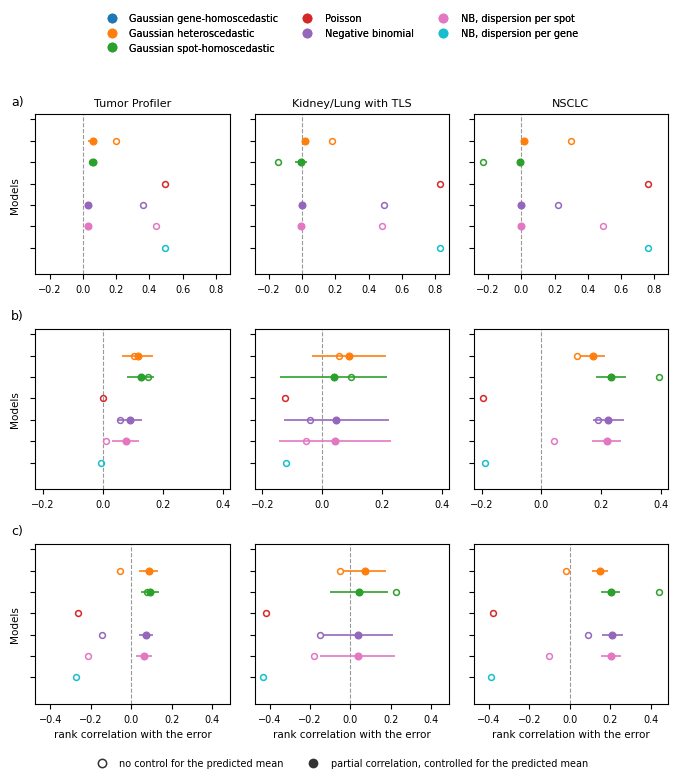

## FIGURE  fig_canal2_gene_axis_pr_classic3_canal2_uncertainty.pdf
## TITLE   Predicted uncertainty against prediction error on the gene axis, before and after controlling for the predicted mean
## CAPTION One row per predictive head. Filled circle: the partial Spearman correlation
## CAPTION between the predicted uncertainty and the absolute error within a group, the
## CAPTION predicted mean being partialled out as a rank covariate. Cross: the same
## CAPTION correlation without that control. The horizontal gap between the two IS the
## CAPTION effect of the confounder.
## CAPTION Bar: Student-t 95% interval over the 8 held-out donors.
## CAPTION a) error definition: |y - mu|, all (spot, gene) entries, zeros included.
## CAPTION b) error definition: |y - mu|, detected entries only (y > 0).
## CAPTION c) error definition: |log y - log mu|, detected entries only (y > 0).
## CAPTION Grouping: one group per gene and slide, ranking the error across the spots where that gene is detected.
#

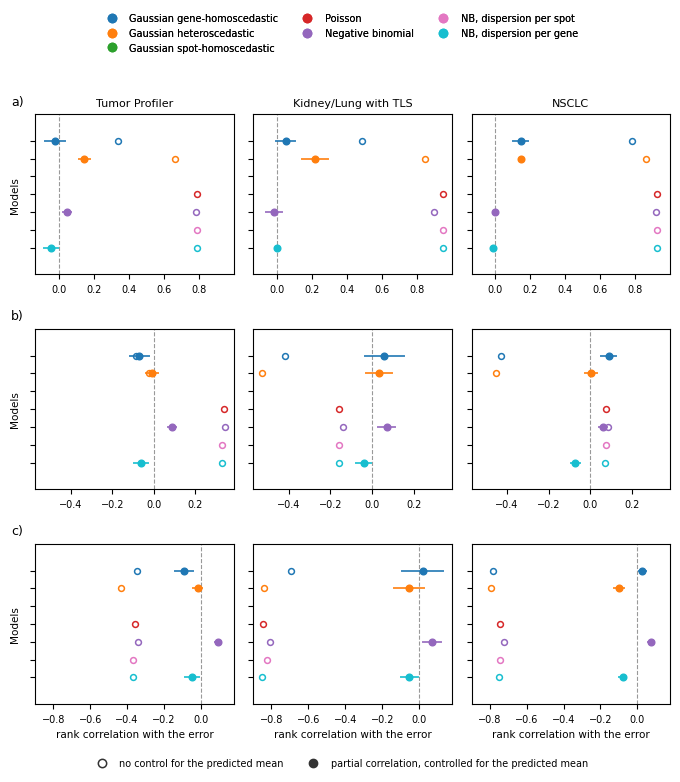

## FIGURE  fig_canal2_spot_axis_pr_classic3_canal2_uncertainty.pdf
## TITLE   Predicted uncertainty against prediction error on the spot axis, before and after controlling for the predicted mean
## CAPTION One row per predictive head. Filled circle: the partial Spearman correlation
## CAPTION between the predicted uncertainty and the absolute error within a group, the
## CAPTION predicted mean being partialled out as a rank covariate. Cross: the same
## CAPTION correlation without that control. The horizontal gap between the two IS the
## CAPTION effect of the confounder.
## CAPTION Bar: Student-t 95% interval over the 8 held-out donors.
## CAPTION a) error definition: |y - mu|, all (spot, gene) entries, zeros included.
## CAPTION b) error definition: |y - mu|, detected entries only (y > 0).
## CAPTION c) error definition: |log y - log mu|, detected entries only (y > 0).
## CAPTION Grouping: one group per slide and spot, ranking the error across the genes of that spot.
## CAPTION A hea

In [17]:
from matplotlib.lines import Line2D

FIGDIR.mkdir(parents=True, exist_ok=True)

CASE_FIG = {"lin_all": "|y - mu|, all (spot, gene) entries, zeros included",
            "lin_pos": "|y - mu|, detected entries only (y > 0)",
            "log_pos": "|log y - log mu|, detected entries only (y > 0)"}

def fig_show(fig, stem, title, caption):
    """Saves .pdf + .png, displays, then PRINTS title and caption."""
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")
PLOT_MODELS = [m for m in MODELS]          # the _raw stay out of the figure: other error axis

drawn = []      # accumulates BOTH axes. Reset inside the loop, the printed twin below would
                # cover only the last axis while claiming to cover both.
for axis in AXES:
    fig, axes = plt.subplots(len(CASES), len(DATASETS), figsize=(2.3 * len(DATASETS), 2.5 * len(CASES)),
                             sharex="row")
    axes = np.atleast_2d(axes)
    for i, case in enumerate(CASES):
        for j, ds in enumerate(DATASETS):
            ax = axes[i, j]
            # EVERY head keeps its row, even a mute one: Poisson has no controlled value
            # (u = mu exactly) but it has a naive value, and its missing filled marker
            # IS the result. An omitted row would read as missing data.
            # HOLLOW marker = uncontrolled, FILLED = controlled. The interval is drawn only on
            # the controlled one: the naive is a starting point of the reasoning, not a measure
            # (its sign even changes between the two error definitions), giving it an interval
            # would invite reading it as one.
            for y, m in enumerate(PLOT_MODELS):
                r = get(ds, m, case, axis)
                if r is None:
                    continue
                c = MODEL_COLORS.get(m, "0.4")
                nv, pv = r.get("naive", np.nan), r.get("partial", np.nan)
                if np.isfinite(nv):
                    ax.plot([nv], [y], "o", ms=4.2, mfc="none", mec=c, mew=1.1, zorder=3)
                if not np.isfinite(pv):
                    continue
                lo, hi = r.get("partial_lo", np.nan), r.get("partial_hi", np.nan)
                if np.isfinite(lo):
                    ax.plot([lo, hi], [y, y], color=c, lw=1.4, alpha=0.85, zorder=3)
                ax.plot([pv], [y], "o", ms=4.8, color=c, zorder=4)
                drawn.append(dict(axis=axis, case=case, dataset=ds, model=m,
                                  naive=r.get("naive"), partial=r["partial"], lo=lo, hi=hi))
            ax.axvline(0.0, color="0.6", lw=0.8, ls="--", zorder=1)
            ax.set_yticks(range(len(PLOT_MODELS)))
            ax.set_yticklabels([])          # the COLOR identifies the head, cf. legend on top
            if j == 0:
                ax.set_ylabel("Models", fontsize=7.5)
                # Row letter. The full error descriptor lives in the PRINTED CAPTION, not in
                # the figure: that is what keeps the panels narrow, and it is that text that
                # goes into the .tex anyway.
                ax.text(-0.06, 1.04, f"{'abc'[i]})", transform=ax.transAxes,
                        ha="right", va="bottom", fontsize=9)
            ax.invert_yaxis()
            ax.tick_params(axis="x", labelsize=7)
            if i == len(CASES) - 1:
                ax.set_xlabel("rank correlation with the error", fontsize=7.5)
            ax.margins(y=0.25)
            if i == 0:
                ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
    model_handles = [Line2D([], [], marker="o", ls="", color=MODEL_COLORS.get(m, "0.4"),
                            label=MODEL_LABELS.get(m, m)) for m in PLOT_MODELS]
    cond = [Line2D([], [], marker="o", ls="", mfc="none", mec="#333333", mew=1.1,
                   label="no control for the predicted mean"),
            Line2D([], [], marker="o", ls="", color="#333333",
                   label="partial correlation, controlled for the predicted mean")]
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    leg1 = fig.legend(handles=model_handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
                      ncol=3, frameon=False, fontsize=7)
    fig.add_artist(leg1)
    fig.legend(handles=cond, loc="lower center", ncol=2, frameon=False, fontsize=7,
               bbox_to_anchor=(0.5, -0.03))
    fig_show(fig, FIGDIR / f"fig_canal2_{axis}_axis_{RUN_ID}_{CANAL2}",
             f"Predicted uncertainty against prediction error on the {axis} axis, before and "
             f"after controlling for the predicted mean",
             [f"One row per predictive head. Filled circle: the partial Spearman correlation",
              f"between the predicted uncertainty and the absolute error within a group, the",
              f"predicted mean being partialled out as a rank covariate. Cross: the same",
              f"correlation without that control. The horizontal gap between the two IS the",
              f"effect of the confounder.",
              f"Bar: Student-t 95% interval over the {int(RES['K'].max())} held-out donors.",
              *[f"{'abc'[k]}) error definition: {CASE_FIG[c]}." for k, c in enumerate(CASES)],
              f"Grouping: {'one group per gene and slide, ranking the error across the spots '
                          'where that gene is detected' if axis == 'gene' else 
                          'one group per slide and spot, ranking the error across the genes of '
                          'that spot'}.",
              f"A head absent from a panel is MUTE there by construction, not missing: its",
              f"variance parameter is constant along that axis, so it carries no degree of",
              f"freedom independent of the predicted mean."])

DRAWN = pd.DataFrame(drawn) if drawn else pd.DataFrame()
print("\n" + "=" * 118)
print("THE PRINTED TWIN OF BOTH FIGURES -- exactly the drawn values, nothing more")
print("=" * 118)
for axis in AXES:
    for case in CASES:
        sub = DRAWN[(DRAWN["axis"] == axis) & (DRAWN["case"] == case)] if not DRAWN.empty else DRAWN
        if sub.empty:
            continue
        print(f"\n[axis {axis} | {case}]")
        print(f"    {'cohort':<22s} {'head':<40s} {'naive':>9s} {'control':>9s} {'95% CI':>22s}")
        for _, r in sub.iterrows():
            ci = (f"[{r['lo']:+.4f}, {r['hi']:+.4f}]" if np.isfinite(r["lo"]) else "n/a")
            nv = f"{r['naive']:+.4f}" if r["naive"] is not None and np.isfinite(r["naive"]) else "    n/a"
            print(f"    {DATASET_LABELS.get(r['dataset'], r['dataset']):<22s} "
                  f"{MODEL_LABELS.get(r['model'], r['model']):<40s} {nv:>9s} "
                  f"{r['partial']:>+9.4f} {ci:>22s}")